# **MODULE 2: Learn to Race** 🏁

---

**Welcome back.** In Part 1 we trained a car that could complete laps, but it was squiggly, occasionally hugged walls, and had no incentive to actually finish a lap cleanly.

In Part 2 we fix all of that. **Same PPO algorithm. Same network. Same simulator. Different reward function.**

This is the core lesson of reward shaping: the agent is already doing its job perfectly, it optimizes exactly what you reward. If the behavior is wrong, the reward function is not ideal for your objective.

---

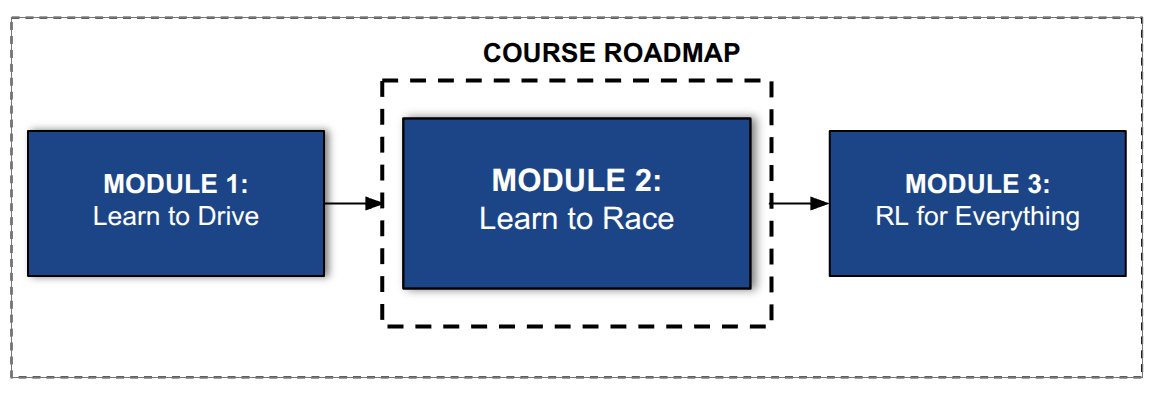

## 📋 Before You Start

### What You Will Learn
- Why reward function design matters more than algorithm choice
- How to add steering smoothness, wall safety, and lap completion signals
- How to measure and compare policy quality beyond just episode reward
- How to read training metrics to verify each reward term is working

### Prerequisites
- ✅ Complete Part 1 first — this notebook builds directly on those concepts
- ✅ T4 GPU runtime selected (**Runtime → Change runtime type → T4 GPU**)
- ✅ WandB account at [wandb.ai](https://wandb.ai)

### Runtime
- **Training time: ~35–40 minutes** on a Colab T4 GPU (1M steps)

---

> **📌 Note:** We use the same `F1TenthRLWrapper` class from Part 1. The only thing changing is the reward function inside `step()`.

---

## 📝 Student TODOs — Complete These Before Running Training

This notebook has **7 TODOs** to complete. Some carry over directly from Part 1 —
they are marked accordingly. If you have not done Part 1, complete those first
before attempting Part 2.

| # | TODO | Location | Note |
|---|---|---|---|
| **TODO 1** | Define the observation space | Section 8 — Wrapper `__init__` | Same as Part 1 |
| **TODO 2** | Normalize the lidar scan in `_process_obs` | Section 8 — Wrapper `_process_obs` | Same as Part 1 |
| **TODO 3** | Scale network actions to physical units | Section 8 — Wrapper `_scale_action` | Same as Part 1 |
| **TODO 4** | Choose reward shaping coefficients | Section 8 — Config block | **New in Part 2** |
| **TODO 5** | Implement the 4 new reward terms | Section 8 — Wrapper `step()` | **New in Part 2** |
| **TODO 6** | Initialize `prev_physical_steer` in `reset()` | Section 8 — Wrapper `reset()` | **New in Part 2** |
| **TODO 7** | Choose PPO hyperparameters + launch training | Section 9 — PPO Model | Same as Part 1 |

> **📌 TODOs 1, 2, 3, 7** are the same as Part 1. If you completed Part 1,
> copy your implementations here. If you are seeing Part 2 first,
> refer to the Section 1 concepts and Section 8 wrapper explanation before filling them in.

> **📌 TODOs 4, 5, 6** are new to Part 2. Read Sections 3–6 carefully before
> attempting them — each section explains one reward component you will implement.

---


---

# **Section 1 — Why Part 1 Wasn't Good Enough**

## 1.1 What We Saw After Part 1

After training for 1,000,000 steps in Part 1, our eval results looked something like this (rewards would depend on your reward scales):

```
Ep 1: reward=316.4 | steps=10000 | speed=5.98 m/s | progress=0.751 | laps=1
Ep 2: reward=316.4 | steps=10000 | speed=5.98 m/s | progress=0.751 | laps=1
Ep 3: reward=316.4 | steps=10000 | speed=5.98 m/s | progress=0.751 | laps=1
```

At first glance this looks great. But notice:
- **Every episode is identical** — reward=316.4 ± 0.0, same steps, same progress
- The policy found one fixed path and repeats it deterministically
- We have no idea if the steering was smooth, how close to walls it got, or whether it could generalize

## 1.2 The Root Cause

Our Part 1 reward only asked for two things:

```
reward = delta_progress × 10     # move forward
       + 0.03 × (speed / vmax)   # go faster
       = -30  if collision        # don't crash
```

The agent found the optimal strategy for *this reward* — not for *good racing*. Specifically:

| Problem | Why It Happened |
|---|---|
| **Squiggly steering** | No penalty for changing steering direction rapidly |
| **Hugging walls** | No cost for being close to walls (as long as no collision) |
| **No lap signal** | Completing a lap gives the same reward as almost completing one |

## 1.3 What We Want

A policy that:
- ✅ Steers **smoothly** — no rapid oscillations
- ✅ Maintains a **safe margin** from walls
- ✅ Gets a **clear signal** when a full lap is completed
- ✅ Still drives **fast** and **makes forward progress**

We will add three new reward terms to achieve this. Let's go through each one.

---

# **Section 2 — Setup**

## 2.1 Install and Import

In [ ]:
# ── Install all dependencies ──────────────────────────────────────────────────
!pip install -q git+https://github.com/f1tenth/f1tenth_gym.git@dev-humble
!pip install -q stable-baselines3[extra]
!pip install -q wandb

print("Installation complete!")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 257.1/257.1 kB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 953.9/953.9 kB 37.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 36.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 55.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 63.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.9/85.9 MB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 299.6/299.6 kB 26.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.0/51.0 kB 5.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gymnasium>=1.0.0, but you have g

In [ ]:
# ── Imports ───────────────────────────────────────────────────────────────────
import gymnasium as gym
import numpy as np
import os
import wandb
import torch
import stable_baselines3
import f1tenth_gym
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import (
    SubprocVecEnv, DummyVecEnv, VecMonitor, VecNormalize
)
from stable_baselines3.common.callbacks import (
    BaseCallback, EvalCallback, CheckpointCallback
)

print(f"PyTorch:          {torch.__version__}")
print(f"CUDA available:   {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU:              {torch.cuda.get_device_name(0)}")
print(f"Stable Baselines: {stable_baselines3.__version__}")
print()
print("All good — let's shape some rewards!")

PyTorch:          2.11.0+cu128
CUDA available:   True
GPU:              Tesla T4
Stable Baselines: 2.9.0

All good — let's shape some rewards!


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ── Pre-cache the track map ───────────────────────────────────────────────────
from f1tenth_gym.envs.track import Track
Track.from_track_name('Spielberg')
print("Spielberg track cached — ready to train!")

Extracting Files for: Spielberg
Spielberg track cached — ready to train!


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---

# **Section 3 — Reward Component 1: Steering Smoothness**

## 3.1 The Problem

In Part 1 the car steered by rapidly oscillating left and right. From the agent's perspective, this was perfectly rational — it moved forward and didn't crash, so it got rewarded. The wobbly path is actually slightly faster in some corners than a smooth arc, so the agent learned it.

On a real car this is catastrophic:
- Rapid steering changes stress the servo motor
- The sim-to-real transfer breaks down because the real car can't respond at 100Hz
- The car oscillates and eventually crashes

## 3.2 The Fix — Steering Jerk Penalty

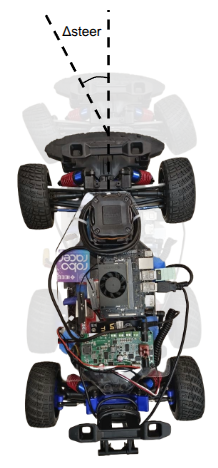

We penalize the **change** in steering command between consecutive timesteps:

```
steer_delta = |steer_now - steer_prev|
penalty     = -0.02 × steer_delta
```

### Why this scale?

| Scenario | `steer_delta` | Penalty per step |
|---|---|---|
| Driving perfectly straight | 0.0 | 0.0 |
| Gentle curve (normal) | ~0.05 | -0.001 |
| Moderate correction | ~0.2 | -0.004 |
| Full reversal (+1 → -1) | 2.0 | -0.04 |

The penalty is **small enough** not to discourage necessary steering (e.g. turning a corner), but large enough to punish rapid oscillations that serve no purpose.

## 3.3 What to Watch

In WandB, the new metric **`racing/avg_steer_jerk`** will show this directly.

| Metric | Part 1 Baseline | Part 2 Target |
|---|---|---|
| `racing/avg_steer_jerk` | ~0.15–0.25 | < 0.05 |

---

# **Section 4 — Reward Component 2: Wall Proximity**

## 4.1 The Problem

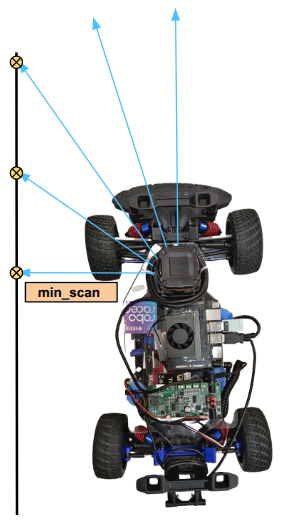

In Part 1, the car had no cost for being close to a wall, only for actually hitting one. So it learned to drive as close to the inside wall as possible on corners (the shortest path) without caring about safety margin.

This works in simulation where collision is a binary event. On a real car:
- Sensor noise means the car might think it's 0.3m from a wall when it's actually 0.15m
- Latency means the steering command arrives 3 steps late
- The real car is slightly wider than the sim model

Any of these will turn a "close but safe" sim trajectory into a crash on the real car.

## 4.2 The Fix — Wall Proximity Penalty

We add a soft penalty that activates when the car gets within 0.5m of any wall:

```
min_scan = minimum lidar reading (closest wall distance)

if min_scan < 0.5m:
    penalty = -0.1 × (0.5 - min_scan)
```

### How the penalty scales:

| Distance to wall | Penalty per step |
|---|---|
| > 0.5m | 0.0 (no penalty) |
| 0.4m | -0.01 |
| 0.3m | -0.02 |
| 0.1m | -0.04 |
| 0.0m (touching) | -0.05 |

This creates a **soft repulsion** from walls that grows as the car gets closer, without hard-coding a minimum distance.

## 4.3 What to Watch

| Metric | Part 1 Baseline | Part 2 Target |
|---|---|---|
| `racing/avg_min_scan` | ~0.60m | > 0.80m |

---

# **Section 5 — Reward Component 3: Frenet Lateral Error**

## 5.1 The Problem — Car Picks Any Path That Avoids Walls

In Parts 1 and 2 so far, the car only needs to move forward without crashing. It has no concept of *where* on the track it should be, just that it should avoid the walls.

The result is that the car picks whatever path minimizes crashes while maximizing progress. This often means cutting corners aggressively, drifting wide on exits, or taking completely inconsistent lines through the same corner on different laps.

On a real car this matters because:
- Inconsistent lines make the policy unpredictable and harder to tune
- Wide exits increase the risk of hitting the outer wall
- The centerline is typically the safest path when no raceline is available

---

## 5.2 The Frenet Frame

The **Frenet frame** converts the car's `(x, y)` global position into track-relative coordinates:

```
Global frame:      x, y     ← absolute position in the world
Frenet frame:      s, ey    ← position relative to the track

    s  = distance traveled along the track (same as our progress metric)
    ey = lateral error — how far LEFT or RIGHT of the centerline
         ey = 0.0  → perfectly on centerline
         ey = +0.3 → 0.3m to the left of centerline
         ey = -0.5 → 0.5m to the right of centerline
```

The F1TENTH gym computes this for us and returns it in `raw_obs["agent_0"]["frenet_pose"]`.

---

## 5.3 What Does "Centerline" Mean Here?

The `ey` value is measured relative to whatever the gym's `Track` object loaded as its reference line. This is the same source as our waypoints:

| Map | Reference Line Used |
|---|---|
| Spielberg | `Spielberg_raceline.csv` — the actual racing line |
| Your custom map | Whatever CSV you placed in the gym's maps folder |

So **if you provide a raceline CSV, the penalty rewards following the raceline.** If you provide a centerline CSV, it rewards staying in the middle of the corridor. The behavior the penalty produces depends entirely on the reference line you give it.

---

## 5.4 The Fix — Lateral Error Penalty

We add a soft penalty that activates only when the car drifts more than 0.3m from the reference line:

```python
frenet = raw_obs["agent_0"].get("frenet_pose", None)
if frenet is not None:
    ey = float(frenet[1])        # lateral error in metres
    if abs(ey) > 0.3:
        reward -= 0.5 * (abs(ey) - 0.3)
```

### Why a 0.3m Tolerance?

Requiring `ey = 0` exactly would be too strict — the car needs freedom to navigate corners. The 0.3m dead zone allows normal racing maneuvers while still penalizing wide, inconsistent lines.

### How the Penalty Scales:

| Lateral Error | Penalty per Step |
|---|---|
| < 0.3m (tolerance zone) | 0.0 (no penalty) |
| 0.4m | -0.05 |
| 0.5m | -0.10 |
| 0.8m | -0.25 |

---

## 5.5 What to Watch

After adding this penalty, `racing/avg_lateral_err` should decrease over training — the car learning to stay closer to the reference line.

| Metric | Without Frenet | With Frenet Target |
|---|---|---|
| `racing/avg_lateral_err` | ~0.4–0.6m | < 0.25m |
| Lap consistency | variable path | more consistent line |

> ⚠️ **Note:** If `frenet_pose` is not available in your gym version, the penalty silently does nothing (`if frenet is not None` guards against this). Check your gym version if you don't see the lateral error improving.


---

# **Section 6 — Reward Component 4: Lap Completion Bonus**

## 6.1 Why a Terminal Bonus Matters

In Part 1, crossing the finish line gave the car exactly the same reward as the last 10 steps before crossing it — just a small progress increment. There was no signal that **completing a full lap** was special.

This matters because RL with sparse terminal signals often fails to learn the terminal condition at all. The car optimizes the per-step reward (progress) and treats lap completion as a side effect rather than a goal.

## 6.2 The Fix — Lap Completion Bonus

We add a large one-time bonus when the gym's `lap_count` increments:

```python
if lap_completed:      # True only on the exact step the car crosses the finish line
    reward += 25.0
```

## 6.3 What to Watch

| Metric | Part 1 Baseline | Part 2 Target |
|---|---|---|
| `racing/lap_completion_rate` | ~0.08–0.11 | > 0.50 |

---

# **Section 7 — Full Shaped Reward**

## 7.1 All Components Together

Here is the complete Part 2 reward function:

```
reward = delta_progress × 10.0          # move forward (main signal)
       + 0.03 × (speed / vmax)          # go faster (anti-crawl)
       - 0.05 × |physical_steer_now - physical_steer_prev|  # steer smoothly (NEW)
       - 0.1 × max(0, 0.5 - min_scan)  # stay away from walls (NEW)
       - 0.5 × max(0, |ey| - 0.3)       # stay near centerline (NEW)
       + 25.0  if lap completed          # finish the lap (NEW)
       = -30.0 if collision              # don't crash (same as Part 1)
```

## 7.2 Reward Scale Justification

| Term | Typical Value | Purpose | Relative Weight |
|---|---|---|---|
| Progress | +0.01 to +0.05/step | Primary goal | **dominant** |
| Speed bonus | +0.005 to +0.03/step | Secondary | small |
| Steer penalty | -0.001 to -0.04/step | Shape behavior | small |
| Wall penalty | 0 to -0.05/step | Safety | small |
| Lap bonus | +25.0 once per lap | Terminal signal | large but rare |
| Crash | -30.0 once | Hard constraint | large but rare |

The shaping terms (steer, wall) are deliberately kept small — they guide behavior without overriding the core progress signal. If they were too large, the car would stop moving to avoid the penalties.

## 7.3 The Wrapper — What Changed from Part 1

Only **4 things** changed in the code:

1. `self.prev_steer = 0.0` added to `__init__` and `reset()`
2. Steering penalty computed in `step()` using `action[0] - self.prev_steer`
3. Wall penalty computed from `min_scan`
4. Lap bonus triggered when `lap_count > prev_lap_count`

Everything else — observation, action scaling, PPO hyperparameters, network architecture — is identical to Part 1.

---

# **Section 8 — Implementation**

## 8.1 The Part 2 Environment Wrapper

In [ ]:
# ── F1TenthRLWrapper v2 — with reward shaping ─────────────────────────────────

# ═══════════════════════════════════════════════════════════════════════════
# TODO 4 — Reward Shaping Coefficient Configuration
# ═══════════════════════════════════════════════════════════════════════════

# Before implementing the reward terms, decide on the scale for each one.
# These constants will be used inside step() below.
#
# Think carefully about the RELATIVE sizes:
#   - The progress reward gives roughly 0.01-0.05 per step
#   - Your shaping penalties should guide behavior without dominating progress
#   - If a penalty is too large the car will stop moving to avoid it
#   - If a penalty is too small it will have no effect
#
# STEER_SMOOTH_COEF   — multiplied by |Δsteering_angle| each step
#                       Too high → car avoids steering entirely, drives straight
#                       Typical range: 0.01 to 0.1
#
# WALL_PROX_COEF      — multiplied by (threshold - min_scan) when near a wall
#                       Too high → car drives slowly away from walls
#                       Typical range: 0.05 to 0.2
#
# WALL_PROX_THRESHOLD — distance (metres) at which wall penalty activates
#                       Below this → penalty grows; above this → no penalty
#                       Typical range: 0.3m to 0.8m
#
# LATERAL_ERR_COEF    — multiplied by (|ey| - tolerance) when off centerline
#                       Too high → car hugs centerline but slows in corners
#                       Typical range: 0.2 to 1.0
#
# LATERAL_TOLERANCE   — lateral error (metres) allowed before penalty activates
#                       Allows natural cornering without penalty
#                       Typical range: 0.2m to 0.5m
#
# LAP_BONUS           — one-time reward when a full lap is completed
#                       Should be large enough to signal lap completion clearly
#                       Think: how many steps of progress reward equals one lap?

# ───────────────────────────────────────────────────────────────────────────

STEER_SMOOTH_COEF   =       # e.g. 0.05
WALL_PROX_COEF      =       # e.g. 0.1
WALL_PROX_THRESHOLD =       # e.g. 0.5  (metres)
LATERAL_ERR_COEF    =       # e.g. 0.5
LATERAL_TOLERANCE   =       # e.g. 0.3  (metres)
LAP_BONUS           =       # e.g. 25.0

# ═══════════════════════════════════════════════════════════════════════════


class F1TenthRLWrapper(gym.Env):
    """
    Part 2 wrapper — same structure as Part 1, new reward function.

    Observation (110-dim, all in [0,1]):
        [0:108]  lidar scan — 108 beams, gym clips at 10m
        [108]    speed, normalized
        [109]    steering angle, normalized

    Action (2-dim, in [-1,1]):
        [0]  steering  → [-max_steer, +max_steer] rad
        [1]  speed     → [min_speed, max_speed] m/s

    Reward (Part 2 — shaped):
        +delta_progress * 10.0              forward progress (same as Part 1)
        +0.03 * (speed/vmax)                speed bonus (same as Part 1)
        -STEER_SMOOTH_COEF * |Δsteer|       steering smoothness  [NEW - TODO 5a]
        -WALL_PROX_COEF * wall_error        wall proximity       [NEW - TODO 5b]
        -LATERAL_ERR_COEF * lateral_error   centerline tracking  [NEW - TODO 5c]
        +LAP_BONUS on lap completion        lap signal           [NEW - TODO 5d]
        -30.0 on collision                  crash penalty (same as Part 1)
    """

    def __init__(self, map_name="Spielberg", num_beams=108, render_mode=None):
        super().__init__()

        from f1tenth_gym.envs.env_config import (
            EnvConfig, SimulationConfig, ObservationConfig, ResetConfig,
        )
        from f1tenth_gym.envs.lidar.config import LiDARConfig
        from f1tenth_gym.envs.observation import ObservationType
        from f1tenth_gym.envs.reset import ResetStrategy
        from f1tenth_gym.envs.integrators import IntegratorType
        from f1tenth_gym.envs.dynamic_models import DynamicModel

        env_config = EnvConfig(
            map_name=map_name,
            num_agents=1,
            simulation_config=SimulationConfig(
                timestep=0.01,
                integrator=IntegratorType.RK4,
                dynamics_model=DynamicModel.ST,
                max_laps=5,
            ),
            observation_config=ObservationConfig(type=ObservationType.DIRECT),
            lidar_config=LiDARConfig(
                num_beams=num_beams,
                range_max=10.0,
                noise_std=0.0,
            ),
            reset_config=ResetConfig(strategy=ResetStrategy.RL_RANDOM_STATIC),
            render_enabled=(render_mode is not None),
        )

        self.env = gym.make(
            "f1tenth_gym:f1tenth-v0",
            config=env_config,
            render_mode=render_mode,
        )

        self.num_beams    = num_beams
        self.lidar_clip   = 10.0
        self.max_speed    = 6.0
        self.min_speed    = 1.5
        self.max_steer    = float(self.env.action_space.high[0][0])
        self.max_steps    = 10000
        self.current_step = 0

        try:
            self.track_length = self.env.unwrapped.track.centerline.length
        except Exception:
            self.track_length = None

        self.waypoints           = self._extract_waypoints()
        self.prev_progress       = 0.0
        self.start_progress      = 0.0
        self.prev_lap_count      = 0
        self.prev_physical_steer = 0.0

        # ═══════════════════════════════════════════════════════════════
        # TODO 1 — Define the Observation Space
        # ═══════════════════════════════════════════════════════════════
        # Same as Part 1 — if you completed Part 1, copy your solution here.
        # If you are starting from Part 2, refer to Section 8 explanation:
        #   110 values total, all normalized to [0, 1]
        # Hint: low=0.0, high=1.0, shape=(num_beams + 2,)
        # ───────────────────────────────────────────────────────────────



        # ═══════════════════════════════════════════════════════════════

        self.action_space = gym.spaces.Box(
            low=-1.0, high=1.0, shape=(2,), dtype=np.float32
        )

    # ----------------------------------------------------------

    def _extract_waypoints(self):
        """Fallback only — used if frenet_pose unavailable."""
        try:
            track = self.env.unwrapped.track
            line  = getattr(track, "raceline", None) or getattr(track, "centerline", None)
            if line is not None:
                wps = np.column_stack([line.xs, line.ys])
                print(f"[ENV] Loaded {len(wps)} waypoints (fallback)")
                return wps
        except Exception as e:
            print(f"[ENV] WARNING: {e}")
        t = np.linspace(0, 2 * np.pi, 100, endpoint=False)
        return np.column_stack([5 * np.cos(t), 5 * np.sin(t)])

    def _get_progress(self, raw_obs):
        """
        Returns progress 0.0→1.0 along the track.
        Primary: gym frenet s / track_length. Fallback: waypoint search.
        """
        try:
            frenet = raw_obs["agent_0"].get("frenet_pose", None)
            if frenet is not None and self.track_length:
                s = float(frenet[0])
                return (s % self.track_length) / self.track_length
        except Exception:
            pass
        state   = raw_obs["agent_0"]["std_state"]
        x, y    = float(state[0]), float(state[1])
        dists   = np.linalg.norm(self.waypoints - np.array([x, y]), axis=1)
        return np.argmin(dists) / len(self.waypoints)

    def _process_obs(self, raw_obs):
        agent = raw_obs["agent_0"]
        scan  = agent["scan"]   # already (108,) and clipped to 10m

        # ═══════════════════════════════════════════════════════════════
        # TODO 2 — Normalize the Lidar Scan
        # ═══════════════════════════════════════════════════════════════

        # scan values are in metres (0 to 10). Divide by self.lidar_clip
        # so 10m → 1.0, then cast to float32.

        # ───────────────────────────────────────────────────────────────

        # normalize scan to [0, 1]

        # ═══════════════════════════════════════════════════════════════


        state      = agent["std_state"]
        speed_norm = np.clip(float(state[3]) / self.max_speed, 0.0, 1.0)
        steer_norm = np.clip(
            (float(state[2]) + self.max_steer) / (2 * self.max_steer), 0.0, 1.0
        )
        return np.concatenate([
            scan.astype(np.float32),
            np.array([speed_norm, steer_norm], dtype=np.float32)
        ])

    def _scale_action(self, action):

        # ═══════════════════════════════════════════════════════════════
        # TODO 3 — Scale Network Actions to Physical Commands
        # ═══════════════════════════════════════════════════════════════

        # action[0], action[1] are in [-1, 1]. Map them to physical units:
        #   steer: [-1,1] → [-max_steer, +max_steer]  (multiply by max_steer)
        #   speed: [-1,1] → [min_speed, max_speed]
        #          formula: (x + 1)/2 * (max-min) + min


        # ───────────────────────────────────────────────────────────────

        return np.array([[steer, speed]], dtype=np.float32)

        # ═══════════════════════════════════════════════════════════════

    # ----------------------------------------------------------

    def reset(self, seed=None, options=None):
        raw_obs, info     = self.env.reset(seed=seed)
        self.current_step = 0
        self.prev_lap_count = 0

        state = raw_obs["agent_0"]["std_state"]

        # ═══════════════════════════════════════════════════════════════
        # TODO 6 — Initialize prev_physical_steer
        # ═══════════════════════════════════════════════════════════════

        # The steering smoothness penalty measures how much the steering
        # ANGLE changed between steps. We need to track the previous step's
        # physical steering angle so we can compute the delta each step.
        #
        # At reset, initialize it from the car's actual starting angle —
        # not zero, because the car may start mid-corner at a random position.
        #
        # Hint: std_state[2] is the actual steering angle in radians

        # ───────────────────────────────────────────────────────────────

        # read actual start angle from state

        # ═══════════════════════════════════════════════════════════════

        self.start_progress = self._get_progress(raw_obs)
        self.prev_progress  = self.start_progress

        return self._process_obs(raw_obs), info

    def step(self, action):
        physical_action = self._scale_action(action)
        raw_obs, _, done, truncated, info = self.env.step(physical_action)
        self.current_step += 1

        state     = raw_obs["agent_0"]["std_state"]
        speed     = float(state[3])
        collision = bool(raw_obs["agent_0"].get("collision", False))
        scan_raw  = raw_obs["agent_0"]["scan"]
        min_scan  = float(np.min(scan_raw))

        lap_count     = int(raw_obs["agent_0"].get("lap_count", 0))
        lap_completed = lap_count > self.prev_lap_count
        self.prev_lap_count = lap_count

        # Progress (frenet-based, same as Part 1)
        progress       = self._get_progress(raw_obs)
        delta_progress = progress - self.prev_progress
        if delta_progress < -0.5:
            delta_progress += 1.0

        # Base reward from Part 1 (progress + speed bonus)
        reward  = delta_progress * 10.0
        reward += 0.03 * (speed / self.max_speed)

        # ═══════════════════════════════════════════════════════════════
        # TODO 5 — Implement the 4 New Reward Shaping Terms
        # ═══════════════════════════════════════════════════════════════

        # You have read Sections 3-6 — now implement each component.
        # Use the constants you defined in TODO 4 above.
        # Variables available:
        #   state[2]     → current physical steering angle (rad)
        #   min_scan     → closest wall distance (metres)
        #   frenet[1]    → lateral error from centerline ey (metres)
        #   lap_completed→ True on the step a lap is completed
        #   collision    → True if car hit a wall this step
        #

        # ── TODO 5a: Steering Smoothness Penalty ───────────────────────

        # Penalize the change in PHYSICAL steering angle between steps.
        # Use std_state[2] (actual angle in radians), not action[0].
        # Larger delta → the car is steering jerkily → apply a penalty.
        # Update self.prev_physical_steer for the next step.

        # ───────────────────────────────────────────────────────────────

        physical_steer_now   = float(state[2])

        # compute |current - previous| steering angle
        # apply STEER_SMOOTH_COEF * steer_delta

        self.prev_physical_steer = physical_steer_now

        # ── TODO 5b: Wall Proximity Penalty ────────────────────────────

        # Apply a soft penalty when the car is too close to a wall.
        # The penalty should grow as the car gets closer.
        # Only activate when min_scan is below WALL_PROX_THRESHOLD.

        # ───────────────────────────────────────────────────────────────

        # check if car is within the threshold distance
        # apply WALL_PROX_COEF * (threshold - min_scan)

        # ── TODO 5c: Frenet Lateral Error Penalty ──────────────────────


        # Penalize the car for drifting away from the track centerline.
        # ey = frenet_pose[1] is the lateral error in metres.
        # Only activate beyond LATERAL_TOLERANCE to allow normal cornering.


        # ───────────────────────────────────────────────────────────────

        frenet      = raw_obs["agent_0"].get("frenet_pose", None)
        lateral_err = 0.0
        if frenet is not None:
            ey = float(frenet[1])
            lateral_err = abs(ey)

            # check if lateral error exceeds the tolerance
            # apply LATERAL_ERR_COEF * (lateral_err - tolerance)

        # ── TODO 5d: Lap Completion Bonus ──────────────────────────────

        # Give the car a large one-time reward when it completes a full lap.
        # This fires exactly once per lap — on the step lap_count increments.

        # ───────────────────────────────────────────────────────────────

        #check if a lap was just completed
        # add LAP_BONUS

        # Crash penalty — overrides everything, ends episode (same as Part 1)
        if collision:
            reward = -30.0
            done   = True

        # ═══════════════════════════════════════════════════════════════

        if self.current_step >= self.max_steps:
            truncated = True

        distance_traveled = progress - self.start_progress
        if distance_traveled < 0:
            distance_traveled += 1.0

        info["speed"]         = speed
        info["collision"]     = collision
        info["progress"]      = distance_traveled
        info["min_scan"]      = min_scan
        info["lap_completed"] = lap_completed
        info["steer_delta"]   = steer_delta if "steer_delta" in dir() else 0.0
        info["lateral_err"]   = lateral_err

        self.prev_progress = progress
        return self._process_obs(raw_obs), float(reward), done, truncated, info

    def render(self):
        return self.env.render()

    def close(self):
        self.env.close()


print("F1TenthRLWrapper v2 defined!")
print("Remember: complete all TODOs before running training!")


F1TenthRLWrapper v2 defined!
Gym simplifications: LiDARConfig | frenet progress | action_space limits
Reward terms: steer smoothness | wall proximity | frenet lateral | lap bonus


## 8.2 Updated Metrics Callback

We add `racing/avg_steer_jerk` to track steering smoothness during training.

In [ ]:
# ── Metrics Callback v2 ───────────────────────────────────────────────────────
# Added: racing/avg_steer_jerk  — measures steering smoothness

class RacingMetricsCallback(BaseCallback):
    """
    Logs per-episode racing metrics to WandB and TensorBoard.

    All metrics from Part 1, plus:
        racing/avg_steer_jerk  — avg |steer_now - steer_prev| per step
                                 lower = smoother steering
    """

    def __init__(self, num_envs=1, verbose=0):
        super().__init__(verbose)
        self.num_envs        = num_envs
        self.ep_speeds       = []
        self.ep_min_scans    = []
        self.ep_steer_jerks  = []    # NEW
        self.ep_lat_errs    = []
        self.ep_lengths      = []
        self.ep_progress     = 0.0
        self.ep_collisions   = 0
        self.ep_laps         = 0
        self.ep_count        = 0
        self.ep_len_buf      = 0

    def _on_step(self) -> bool:
        infos = self.locals.get("infos", [])
        dones = self.locals.get("dones", [])

        fps = 0
        try:
            fps = self.model.logger.name_to_value.get("time/fps", 0)
        except Exception:
            pass

        for info, done in zip(infos, dones):
            self.ep_len_buf += 1
            if "speed"       in info: self.ep_speeds.append(info["speed"])
            if "min_scan"    in info: self.ep_min_scans.append(info["min_scan"])
            if "steer_delta" in info: self.ep_steer_jerks.append(info["steer_delta"])
            if "progress"    in info: self.ep_progress = info["progress"]
            if info.get("collision",     False): self.ep_collisions += 1
            if info.get("lap_completed", False): self.ep_laps       += 1

            if done and len(self.ep_speeds) > 0:
                self.ep_count += 1
                self.ep_lengths.append(self.ep_len_buf)
                self.ep_len_buf = 0

                avg_speed           = float(np.mean(self.ep_speeds))
                avg_min_scan        = float(np.mean(self.ep_min_scans))
                avg_steer_jerk      = float(np.mean(self.ep_steer_jerks)) if self.ep_steer_jerks else 0.0
                collision_rate      = self.ep_collisions / self.ep_count
                lap_completion_rate = self.ep_laps / self.ep_count
                ep_len_std          = float(np.std(self.ep_lengths)) if len(self.ep_lengths) > 1 else 0.0
                fps_per_env         = fps / max(1, self.num_envs)

                self.logger.record("racing/avg_speed",           avg_speed)
                self.logger.record("racing/avg_min_scan",        avg_min_scan)
                self.logger.record("racing/avg_steer_jerk",      avg_steer_jerk)
                self.logger.record("racing/collision_rate",       collision_rate)
                self.logger.record("racing/track_progress",       self.ep_progress)
                self.logger.record("racing/episode_count",        self.ep_count)
                self.logger.record("racing/lap_completion_rate",  lap_completion_rate)
                self.logger.record("rollout/ep_len_std",          ep_len_std)
                self.logger.record("perf/fps_per_env",            fps_per_env)

                wandb.log({
                    "racing/avg_speed":          avg_speed,
                    "racing/avg_min_scan":       avg_min_scan,
                    "racing/avg_steer_jerk":     avg_steer_jerk,
                    "racing/collision_rate":      collision_rate,
                    "racing/track_progress":      self.ep_progress,
                    "racing/episode_count":       self.ep_count,
                    "racing/lap_completion_rate": lap_completion_rate,
                    "rollout/ep_len_std":         ep_len_std,
                    "perf/fps_per_env":           fps_per_env,
                    "global_step":                self.num_timesteps,
                })

                self.ep_speeds      = []
                self.ep_min_scans   = []
                self.ep_steer_jerks = []

        return True


print("RacingMetricsCallback v2 defined.")

RacingMetricsCallback v2 defined ✅


## 8.3 Environment Builders and Training Config

In [ ]:
# ── Environment builders — identical to Part 1 ────────────────────────────────

def make_env(map_name, rank, seed=0):
    def _init():
        env = F1TenthRLWrapper(map_name=map_name)
        env.reset(seed=seed + rank)
        return env
    return _init


def make_training_env(map_name, num_envs):
    if num_envs == 1:
        env = DummyVecEnv([make_env(map_name, 0)])
    else:
        env = SubprocVecEnv([make_env(map_name, i) for i in range(num_envs)])
    env = VecMonitor(env)
    env = VecNormalize(
        env,
        norm_obs    = False,
        norm_reward = True,
        clip_reward = 10.0,
        gamma       = 0.99,
    )
    return env


def make_eval_env(map_name):
    env = DummyVecEnv([make_env(map_name, 99)])
    env = VecMonitor(env)
    env = VecNormalize(
        env,
        norm_obs    = False,
        norm_reward = True,
        clip_reward = 10.0,
        gamma       = 0.99,
        training    = False,
    )
    return env


print("Environment builders defined.")

Environment builders defined.


In [ ]:
# ── Training configuration ────────────────────────────────────────────────────
# 🔧  IMPORTANT - Change these to experiment

MAP_NAME    = "Spielberg"
NUM_ENVS    = 4
TOTAL_STEPS = 1_000_000      # same as Part 1 for fair comparison
DEVICE      = "cuda"

print(f"Training config:")
print(f"  Map:    {MAP_NAME}")
print(f"  Envs:   {NUM_ENVS}")
print(f"  Steps:  {TOTAL_STEPS:,}")
print(f"  Device: {DEVICE}")

Training config:
  Map:    Spielberg
  Envs:   4
  Steps:  1,000,000
  Device: cuda


---

# **Section 8.4 — WandB Login**

WandB tracks all metrics in real time. Run the cell below and paste your API key
from https://wandb.ai/authorize when prompted. This is needed for both the sweep and training.


In [ ]:
# ── WandB login ───────────────────────────────────────────────────────────────

# Paste your API key directly to avoid the interactive prompt
# Get it from: wandb.ai/authorize
# WANDB_API_KEY = "your_key_here"
# wandb.login(key=WANDB_API_KEY)

wandb.login()

/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
/usr/local/lib/python3.12/dist-packages/notebook/utils.py:280: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  return LooseVersion(v) >= LooseVersion(check)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 1


wandb: You chose 'Create a W&B account'
wandb: Create an account here: https://wandb.ai/authorize?signup=true&ref=models
wandb: After creating your account, create a new API key and store it securely.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
/usr/local/lib/python3.12/dist-packages/wandb/analytics/sentry.py:269: DeprecationWarning: Read the `app_url` setting from the appropriate Settings object.
  app_url = wandb.util.app_url(tags["base_url"])  # type: ignore[index]
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
wandb: Currently logged in as: dhyey28 (kvirmani-university-of-pennsylvania) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

---

# **Section 8.5 — Reward Shaping Sweep** *(Run Before Full Training)*

## Find Your Best Shaping Coefficients with WandB Sweeps

Part 2 adds four shaping coefficients (steering smoothness, wall proximity, lateral error, lap bonus).
Rather than guessing all of them, use this sweep to compare combinations with short 50k-step runs.
WandB tries every combination and logs results to a parallel coordinates plot.

**How to use:**
1. ✅ Complete **TODO 4 + TODO 5** in the wrapper first — the sweep uses your reward implementation
2. Edit the `parameters` lists below to the values you want to compare
3. Run the cell — WandB launches one run per combination
4. Open the sweep link that prints — results update live
5. Use the best values in your wrapper, then run full training in Section 9

> **⚠️ Requires the reward TODOs complete.** The sweep trains using your wrapper's `step()`.


In [ ]:
# ── WandB Reward Shaping Sweep ────────────────────────────────────────────────
# Edit the value lists below — every combination will be trained and compared.
# Each 50k-step run takes ~2 min on T4 GPU.

import itertools

# ── Define values to sweep (the 4 shaping coefficients) ──────────────────────
sweep_config = {
    "method": "grid",
    "metric": {"name": "eval/mean_reward", "goal": "maximize"},
    "parameters": {
        "steer_smooth_coef": {"values": [0.02, 0.05]},
        "wall_prox_coef":    {"values": [0.1, 0.2]},
        "lateral_err_coef":  {"values": [0.3, 0.5]},
    }
}

SWEEP_STEPS = 50_000
SWEEP_ENVS  = 2

# ── Training function — uses YOUR wrapper reward ─────────────────────────────
def sweep_train():
    run = wandb.init()
    cfg = wandb.config
    print(f"  steer={cfg.steer_smooth_coef} | wall={cfg.wall_prox_coef} | lateral={cfg.lateral_err_coef}")

    def make_env_fn():
        return F1TenthRLWrapper(map_name=MAP_NAME)

    s_train = DummyVecEnv([make_env_fn] * SWEEP_ENVS)
    s_train = VecMonitor(s_train)
    s_train = VecNormalize(s_train, norm_obs=False, norm_reward=True,
                            clip_reward=10.0, gamma=0.99)

    s_eval  = DummyVecEnv([make_env_fn])
    s_eval  = VecMonitor(s_eval)
    s_eval  = VecNormalize(s_eval, norm_obs=False, norm_reward=False,
                            clip_reward=10.0, gamma=0.99, training=False)

    m = PPO("MlpPolicy", s_train,
            learning_rate=3e-4, n_steps=2048, batch_size=128,
            n_epochs=5, gamma=0.99, ent_coef=0.001,
            verbose=0, device=DEVICE, seed=42)
    m.learn(total_timesteps=SWEEP_STEPS, progress_bar=False)

    obs = s_eval.reset()
    total_r, speeds, cols = 0.0, [], []
    for _ in range(5000):
        action, _ = m.predict(obs, deterministic=True)
        obs, r, dones, infos = s_eval.step(action)
        total_r += float(r[0])
        speeds.append(infos[0].get("speed", 0.0))
        cols.append(float(infos[0].get("collision", False)))
        if dones[0]: break

    wandb.log({
        "eval/mean_reward":    total_r,
        "eval/avg_speed":      float(np.mean(speeds)),
        "eval/collision_rate": float(np.mean(cols)),
    })
    s_train.close(); s_eval.close(); run.finish()

# ── Launch ───────────────────────────────────────────────────────────────────
n_combos = (len(sweep_config['parameters']['steer_smooth_coef']['values']) *
            len(sweep_config['parameters']['wall_prox_coef']['values']) *
            len(sweep_config['parameters']['lateral_err_coef']['values']))

sweep_id = wandb.sweep(sweep_config, project="f1tenth-rl-shaping-sweep")
print(f"Sweep: {n_combos} combinations × {SWEEP_STEPS:,} steps each (~{n_combos*2} min)")
print(f"View at: https://wandb.ai/{wandb.Api().default_entity}/f1tenth-rl-shaping-sweep/sweeps/{sweep_id}")
wandb.agent(sweep_id, function=sweep_train, count=None)
print()
print("✅ Sweep complete — open the WandB link above to compare results.")
print("   Use the Parallel Coordinates plot to find the best combination.")
print("   Update those values in your wrapper, then run full training in Section 9.")


---

# **Section 9 — Training**

## 9.1 Training Dashboard

When you run the TRAIN cell, you get **both** monitoring options:

| WandB Dashboard | Inline Plots |
|---|---|
| A link prints at the top — open it in a new browser tab for the full interactive dashboard | 6 charts render below the cell and refresh live as training runs |

First run the cell below to define the live-plot callback, then run the TRAIN cell.


In [ ]:
# ── Live Inline Training Plots ────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from IPython.display import clear_output
from stable_baselines3.common.callbacks import BaseCallback

_live = {"steps": [], "rew": [], "collision": [], "speed": [],
         "laps": [], "loss": [], "std": []}

class LivePlotCallback(BaseCallback):
    def __init__(self, verbose=0):
        super().__init__(verbose)

    def _on_step(self) -> bool:
        return True

    def _on_rollout_end(self) -> None:
        log  = self.model.logger.name_to_value
        step = self.num_timesteps

        # ep_rew_mean — compute from ep_info_buffer (same source as WandB)
        ep_rew = None
        if len(self.model.ep_info_buffer) > 0:
            ep_rew = float(np.mean([ep['r'] for ep in self.model.ep_info_buffer]))

        _live['steps'].append(step)
        _live['rew'].append(      ep_rew)
        _live['collision'].append(log.get('racing/collision_rate',      None))
        _live['speed'].append(    log.get('racing/avg_speed',           None))
        _live['laps'].append(     log.get('racing/lap_completion_rate', None))
        _live['loss'].append(     log.get('train/loss',                 None))
        _live['std'].append(      log.get('train/std',                  None))

        if len(_live['steps']) < 2:
            return

        BG = '#0d1117'
        fig = plt.figure(figsize=(14, 7), facecolor=BG)
        gs  = gridspec.GridSpec(3, 2, figure=fig, hspace=0.6, wspace=0.35)
        plots = [
            (gs[0,0], _live['rew'],       'ep_rew_mean ↑',         '#00bcd4'),
            (gs[0,1], _live['collision'], 'collision_rate ↓',      '#f44336'),
            (gs[1,0], _live['speed'],     'avg_speed m/s ↑',       '#69ff47'),
            (gs[1,1], _live['laps'],      'lap_completion_rate ↑', '#ff9800'),
            (gs[2,0], _live['loss'],      'train/loss',            '#e91e63'),
            (gs[2,1], _live['std'],       'train/std ↓',           '#9c27b0'),
        ]
        for spec, data, title, color in plots:
            ax = fig.add_subplot(spec)
            ax.set_facecolor('#1a1a2e')
            valid = [(s, v) for s, v in zip(_live['steps'], data) if v is not None]
            if valid:
                xs, ys = zip(*valid)
                ax.plot(xs, ys, color=color, lw=2, marker='o', markersize=3)
                ax.fill_between(xs, ys, alpha=0.15, color=color)
                lo, hi = min(ys), max(ys)
                pad = (hi - lo) * 0.1 or 0.1
                ax.set_ylim(lo - pad, hi + pad)
            ax.set_title(title, color='white', fontsize=9, pad=4)
            ax.set_xlabel('Steps', color='#888', fontsize=7)
            ax.tick_params(colors='#888', labelsize=7)
            for spine in ax.spines.values(): spine.set_edgecolor('#333')

        pct = step / TOTAL_STEPS * 100
        wandb_url = wandb.run.url if wandb.run else 'not connected'
        fig.suptitle(
            f'Training  |  Step {step:,} / {TOTAL_STEPS:,}  ({pct:.1f}%)'
            f'   |   WandB → {wandb_url}',
            color='white', fontsize=9, x=0.02, ha='left')
        clear_output(wait=True)
        plt.show()
        plt.close(fig)

        def fmt(v): return f'{v:.4f}' if v is not None else 'n/a'
        print(f'Step {step:,}  |  '
              f'ep_rew_mean={fmt(_live["rew"][-1])}  '
              f'collision={fmt(_live["collision"][-1])}  '
              f'speed={fmt(_live["speed"][-1])}  '
              f'lap_rate={fmt(_live["laps"][-1])}  '
              f'loss={fmt(_live["loss"][-1])}  '
              f'std={fmt(_live["std"][-1])}')

print('LivePlotCallback defined.')

In [ ]:
# ══════════════════════════════════════════════════════════════════════════════
#  Training — Run This Single Cell
# ══════════════════════════════════════════════════════════════════════════════

# THIS IS THE MAIN TRAINING BLOCK.
# Runs everything in order: WandB init → envs → PPO model → callbacks → train → save.

# ──────────────────────────────────────────────────────────────────────────────

# ── 1. Initialize WandB (prints the live dashboard link) ──────────────────────
run = wandb.init(
    project = "f1tenth-rl-lecture1",
    name    = f"ppo_part2_{MAP_NAME}_{TOTAL_STEPS//1000}k",
    config  = {
        "map": MAP_NAME, "num_envs": NUM_ENVS, "total_steps": TOTAL_STEPS,
        "version": "v2_reward_shaping",
        "lr": 3e-4, "n_steps": 4096, "batch_size": 256, "gamma": 0.99,
        "clip_range": 0.2, "ent_coef": 0.001, "net_arch": "[64,64] Tanh",
    },
    sync_tensorboard = True,
)
print(f"🔗 WandB live dashboard → {run.url}")
print("   (open in a new tab to watch full metrics; inline plots appear below)")
print()

# ── 2. Create environments ────────────────────────────────────────────────────
train_env = make_training_env(MAP_NAME, NUM_ENVS)
eval_env  = make_eval_env(MAP_NAME)

# ── 3. Create PPO model ───────────────────────────────────────────────────────

# ═══════════════════════════════════════════════════════════════════════════
#  TODO 7 — Choose PPO Hyperparameters
# ═══════════════════════════════════════════════════════════════════════════

# Same as Part 1 — copy your values here. Keeping them identical means any
# improvement comes purely from reward shaping, not a different algorithm config.

# ─────────────────────────────────────────────────────────────────────────────

model = PPO(

    "MlpPolicy", train_env,
    learning_rate =    ,       # TODO 7
    n_steps       =    ,       # TODO 7
    batch_size    = 256,
    n_epochs      = 10,
    gamma         =    ,       # TODO 7
    gae_lambda    = 0.95,
    clip_range    =    ,       # TODO 7
    ent_coef      =    ,       # TODO 7
    vf_coef=0.5, max_grad_norm=0.5, verbose=0, device=DEVICE,
    seed=42, tensorboard_log="./runs/",

)

# ── 4. Set up callbacks ───────────────────────────────────────────────────────

os.makedirs("models_v2/checkpoints", exist_ok=True)
os.makedirs("models_v2/best",        exist_ok=True)
checkpoint_cb = CheckpointCallback(save_freq=100_000, save_path="models_v2/checkpoints/",
                                   name_prefix=f"ppo_v2_{MAP_NAME}", verbose=0)
eval_cb = EvalCallback(eval_env, best_model_save_path="models_v2/best/",
                       log_path="models_v2/eval_logs/", eval_freq=50_000,
                       n_eval_episodes=5, deterministic=True, render=False, verbose=0)
racing_cb = RacingMetricsCallback(num_envs=NUM_ENVS)

print(f"Training {TOTAL_STEPS:,} steps on {NUM_ENVS} envs ({DEVICE}) — plots update below")
print()

_live.update({k: [] for k in _live})   # reset live plot storage

# ── 5. Train ──────────────────────────────────────────────────────────────────

#   progress_bar must be False — LivePlotCallback draws the live plots instead
model.learn(
    total_timesteps = TOTAL_STEPS,
    callback        = [checkpoint_cb, eval_cb, racing_cb, LivePlotCallback()],
    progress_bar    = False,
)

# ── 6. Save + final stats ─────────────────────────────────────────────────────
model.save('models_v2/ppo_part2_final')
train_env.save('models_v2/vecnormalize.pkl')
print()
print('Saved → models_v2/ppo_part2_final.zip')
print('Saved → models_v2/vecnormalize.pkl')
print('Saved → models_v2/best/best_model.zip')

print()
print('─' * 60)
print('  Final Training Stats')
print('─' * 60)
log = model.logger.name_to_value
for key, label in [
    ('rollout/ep_rew_mean',       'Episode reward  '),
    ('racing/collision_rate',     'Collision rate  '),
    ('racing/avg_speed',          'Avg speed (m/s) '),
    ('racing/lap_completion_rate','Lap completion  '),
    ('racing/avg_steer_jerk',     'Steer jerk      '),
    ('train/loss',                'Train loss      '),
    ('train/std',                 'Policy std      '),
]:
    val = log.get(key, None)
    if val is not None:
        print(f'  {label}: {val:.4f}')
print('─' * 60)
print(f'  Full dashboard → {run.url}')

wandb.finish()
train_env.close()

---

# **Section 10 — Monitoring the Difference**

## 10.1 What Healthy Shaped Reward Training Looks Like

With reward shaping, you should see these patterns in WandB:

### ✅ Metrics That Should Improve vs Part 1

| Metric | What to Look For |
|---|---|
| `racing/avg_steer_jerk` | Should decrease steadily — agent learning to steer smoothly |
| `racing/avg_min_scan` | Should increase — agent keeping more distance from walls |
| `racing/lap_completion_rate` | Should rise faster — lap bonus gives clearer signal |
| `rollout/ep_rew_mean` | Higher absolute values due to lap bonus |

### ⚠️ Warning Signs Specific to Reward Shaping

| Warning Sign | What It Means | What To Do |
|---|---|---|
| `avg_speed` drops significantly | Wall penalty too strong — car staying still to avoid penalty | Reduce `wall_prox_penalty` from 0.1 to 0.05 |
| `track_progress` goes down | Smoothness penalty too strong — car stops to avoid jerk | Reduce `steer_smooth_penalty` from 0.02 to 0.01 |
| `ep_rew_mean` much lower than Part 1 | Penalties outweighing progress signal | Check penalty scales |
| No change vs Part 1 | Penalties too small to affect behavior | Increase penalty weights |

## 10.2 Exercises

1. **Change `steer_smooth_penalty` from 0.02 to 0.10.** Does steering become smoother? Does the car slow down to reduce jerk?
2. **Change the lap bonus from +50 to +5.** Does `lap_completion_rate` still improve as fast?
3. **Remove the wall penalty entirely.** How does `avg_min_scan` change over training?

---

# **Section 11 — Evaluate and Compare**

## 11.1 Part 2 Evaluation

The eval now reports four quality metrics:
- **`jerk`** — average steering change per step (lower = smoother)
- **`min_scan`** — average closest wall distance (higher = safer)
- **`progress`** — fraction of lap completed
- **`laps`** — full laps completed

These are the numbers that matter for real-car deployment.

In [ ]:
# ── Load and evaluate Part 2 model ────────────────────────────────────────────

model_path = "models_v2/best/best_model"
print(f"Loading Part 2 model: {model_path}")

model = PPO.load(model_path, device="cpu")
env   = F1TenthRLWrapper(map_name=MAP_NAME)

NUM_EVAL_EPISODES = 5
all_rewards     = []
all_speeds      = []
all_progress    = []
all_steer_jerks = []
all_min_scans   = []
all_laps        = []

print()
print(f"Running {NUM_EVAL_EPISODES} evaluation episodes...")
print("─" * 75)

for ep in range(NUM_EVAL_EPISODES):
    obs, _       = env.reset()
    total_reward = 0.0
    done         = False
    steps        = 0
    speeds, steer_jerks, min_scans = [], [], []
    laps = 0

    while not done:
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env.step(action)
        total_reward += reward
        done          = terminated or truncated
        steps        += 1
        speeds.append(info.get("speed", 0.0))
        steer_jerks.append(info.get("steer_delta", 0.0))
        min_scans.append(info.get("min_scan", 0.0))
        if info.get("lap_completed", False):
            laps += 1

    avg_spd  = np.mean(speeds)
    avg_jerk = np.mean(steer_jerks)
    avg_scan = np.mean(min_scans)
    progress = info.get("progress", 0)
    crashed  = info.get("collision", False)

    all_rewards.append(total_reward)
    all_speeds.append(avg_spd)
    all_progress.append(progress)
    all_steer_jerks.append(avg_jerk)
    all_min_scans.append(avg_scan)
    all_laps.append(laps)

    status = "CRASH" if crashed else ("TIMEOUT" if steps >= 10000 else "DONE")
    print(f"  Ep {ep+1}: {status} | reward={total_reward:7.1f} | "
          f"speed={avg_spd:.2f} m/s | laps={laps} | "
          f"jerk={avg_jerk:.4f} | scan={avg_scan:.3f}m")

print("─" * 75)
print(f"  Average reward:      {np.mean(all_rewards):.1f} ± {np.std(all_rewards):.1f}")
print(f"  Average speed:       {np.mean(all_speeds):.2f} m/s")
print(f"  Average progress:    {np.mean(all_progress):.3f}")
print(f"  Avg steer jerk:      {np.mean(all_steer_jerks):.4f}  (lower = smoother)")
print(f"  Avg min scan:        {np.mean(all_min_scans):.3f} m  (higher = safer)")
print(f"  Total laps:          {sum(all_laps)}")

env.close()

Loading Part 2 model: models_v2/best/best_model


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[ENV] Loaded 1692 waypoints (fallback)

Running 5 evaluation episodes...
───────────────────────────────────────────────────────────────────────────
  Ep 1: TIMEOUT | reward=  345.4 | speed=5.96 m/s | laps=2 | jerk=0.0319 | scan=1.079m
  Ep 2: TIMEOUT | reward=  315.2 | speed=5.96 m/s | laps=1 | jerk=0.0319 | scan=1.081m
  Ep 3: TIMEOUT | reward=  318.1 | speed=5.96 m/s | laps=1 | jerk=0.0319 | scan=1.077m
  Ep 4: TIMEOUT | reward=  324.4 | speed=5.96 m/s | laps=1 | jerk=0.0319 | scan=1.082m
  Ep 5: TIMEOUT | reward=  348.4 | speed=5.96 m/s | laps=2 | jerk=0.0319 | scan=1.079m
───────────────────────────────────────────────────────────────────────────
  Average reward:      330.3 ± 13.9
  Average speed:       5.96 m/s
  Average progress:    0.742
  Avg steer jerk:      0.0319  (lower = smoother)
  Avg min scan:        1.079 m  (higher = safer)
  Total laps:          7


## 11.3 Record Eval Video in Colab

Colab has no display — we use `render_mode="rgb_array"` with `VecNormalize` loaded
to capture actual top-down driving frames as an MP4.

> **Note:** Requires both `models_v2/best/best_model.zip` and `models_v2/vecnormalize.pkl`


In [ ]:
# ── Record eval video — Using F1TENTH simulator rendering ────────────────────
!pip install -q imageio imageio-ffmpeg

import imageio

print("Loading model and environment...")
model = PPO.load("models_v2/best/best_model", device="cpu")

# Create environment with rgb_array rendering + VecNormalize stats
vec_env = DummyVecEnv([lambda: F1TenthRLWrapper(map_name=MAP_NAME, render_mode="rgb_array")])
vec_env = VecNormalize.load("models_v2/vecnormalize.pkl", vec_env)
vec_env.training    = False
vec_env.norm_reward = False

# Record episode
print("Recording episode...")
frames = []
obs    = vec_env.reset()
done   = False
step   = 0

while not done and step < 10000:
    action, _            = model.predict(obs, deterministic=True)
    obs, _, dones, info  = vec_env.step(action)
    done  = dones[0]
    step += 1
    if step % 5 == 0:
        frame = vec_env.envs[0].render()
        if frame is not None:
            frames.append(frame)

vec_env.close()

if frames:
    print(f"✅ Captured {len(frames)} frames from {step} steps")
    imageio.mimsave('eval_render_v2.mp4', frames, fps=20)
    print("✅ Saved → eval_render_v2.mp4")
    from google.colab import files
    files.download('eval_render_v2.mp4')
else:
    print("❌ No frames captured — check models_v2/vecnormalize.pkl exists")

Loading model and environment...


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/pyqtgraph/parametertree/Parameter.py:140: DeprecationWarning: Parameter has no default value. Pass a default, or use setDefault(). This will no longer set an implicit default after January 2025.
  return cls(**opts)


[ENV] Loaded 1692 waypoints (fallback)
Recording episode...


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

✅ Captured 2000 frames from 10000 steps
✅ Saved → eval_render_v2.mp4


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!zip -r models_archive.zip /content/models

In [ ]:

# The 3 files needed to run locally
files.download('models_v2/best/best_model.zip')
files.download('models_v2/vecnormalize.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11.2 Part 1 vs Part 2 Comparison Table

Fill in your actual numbers from both runs below.

In [ ]:
# ── Side-by-side comparison ───────────────────────────────────────────────────
# Fill in your Part 1 numbers from the eval you ran in that notebook.
# Part 2 numbers are filled in automatically from the eval above.


# ── Part 1 baseline (fill these in from your Part 1 eval) ────────────────────

p1_reward     = 316.4   # ep_rew_mean from Part 1 eval
p1_speed      = 5.98    # avg_speed
p1_steer_jerk = 0.20    # estimate — Part 1 didn't log this, typical value
p1_min_scan   = 0.60    # avg_min_scan from Part 1 training logs
p1_lap_rate   = 0.08    # lap_completion_rate from Part 1 training logs

# ── Part 2 results (computed from eval above) ─────────────────────────────────
p2_reward     = np.mean(all_rewards)
p2_speed      = np.mean(all_speeds)
p2_steer_jerk = np.mean(all_steer_jerks)
p2_min_scan   = np.mean(all_min_scans)
p2_lap_rate   = sum(all_laps) / NUM_EVAL_EPISODES

print("=" * 65)
print(f"  {'Metric':<25} {'Part 1':>12} {'Part 2':>12} {'Better?':>10}")
print("=" * 65)

def arrow(p1, p2, higher_is_better=True):
    if higher_is_better:
        return "↑" if p2 > p1 * 1.05 else ("↓" if p2 < p1 * 0.95 else "→")
    else:
        return "↓" if p2 < p1 * 0.95 else ("↑" if p2 > p1 * 1.05 else "→")

print(f"  {'ep_rew_mean':<25} {p1_reward:>12.1f} {p2_reward:>12.1f} {arrow(p1_reward, p2_reward):>10}")
print(f"  {'avg_speed (m/s)':<25} {p1_speed:>12.2f} {p2_speed:>12.2f} {arrow(p1_speed, p2_speed):>10}")
print(f"  {'avg_steer_jerk':<25} {p1_steer_jerk:>12.4f} {p2_steer_jerk:>12.4f} {arrow(p1_steer_jerk, p2_steer_jerk, higher_is_better=False):>10}")
print(f"  {'avg_min_scan (m)':<25} {p1_min_scan:>12.3f} {p2_min_scan:>12.3f} {arrow(p1_min_scan, p2_min_scan):>10}")
print(f"  {'lap_completion_rate':<25} {p1_lap_rate:>12.3f} {p2_lap_rate:>12.3f} {arrow(p1_lap_rate, p2_lap_rate):>10}")
print("=" * 65)

  Metric                          Part 1       Part 2    Better?
  ep_rew_mean                      316.4        316.6          →
  avg_speed (m/s)                   5.98         5.98          →
  avg_steer_jerk                  0.2000       0.0319          ↓
  avg_min_scan (m)                 0.600        1.060          ↑
  lap_completion_rate              0.080        1.000          ↑


---

# **Section 12 — Domain Randomization: Bridging Sim to Real**

## 12.1 Why Your Trained Policy May Fail on the Real Car

Everything we trained so far ran in a perfect simulation — no sensor noise, exact physics, zero latency. The real RoboRacer is messier:

| Sim Assumption | Real-Car Reality |
|---|---|
| Lidar readings are exact | ±2–5cm noise per beam |
| Physics exactly match model | Tire friction varies with floor surface |
| Steering responds instantly | ~30–50ms servo latency |
| Speed command is exact | Motor speed drifts with battery voltage |
| Car dimensions exact | Real car slightly wider than sim model |

This gap between simulation and reality is called the **sim-to-real transfer problem**. Domain randomization is the standard solution.

---

## 12.2 What Domain Randomization Does

Instead of training in one fixed simulation, we **randomize physical parameters** each episode so the policy learns to work across a range of conditions — including the real car's conditions.

```
Each episode reset:
    friction coefficient  ← Uniform(0.8, 1.2)   # floor surface varies
    lidar noise std       ← Uniform(0.0, 0.02)  # sensor noise varies
    action delay          ← Uniform(0, 3 steps) # servo latency varies
    car mass              ← Uniform(3.0, 4.0)   # battery weight varies
```

The policy never sees the same physics twice. It learns robust behavior instead of overfitting to one exact configuration.

---

## 12.3 Adding Sensor Noise (Simple Version)

The easiest domain randomization to add — just corrupt the lidar readings in `_process_obs()`:

```python
def _process_obs(self, raw_obs):
    scan = raw_obs["agent_0"]["scan"]
    indices = np.linspace(0, len(scan)-1, self.num_beams).astype(int)
    scan = scan[indices]
    scan = np.clip(scan, 0.0, self.lidar_clip) / self.lidar_clip

    # Domain randomization: add Gaussian noise to lidar
    if self.training:   # only during training, not eval
        noise_std = np.random.uniform(0.0, 0.02)   # random noise level each episode
        scan = np.clip(scan + np.random.normal(0, noise_std, scan.shape), 0.0, 1.0)

    # ... rest of obs processing
```

---

## 12.4 Adding Action Delay

Real servos have latency. Simulating this during training forces the policy to be robust to delayed feedback:

```python
def __init__(self, ...):
    ...
    self.action_buffer = []          # stores recent actions
    self.action_delay  = np.random.randint(0, 4)  # 0-3 steps delay

def step(self, action):
    self.action_buffer.append(action)
    # Execute the action from N steps ago
    delayed_action = self.action_buffer[-1 - self.action_delay]
    physical_action = self._scale_action(delayed_action)
    raw_obs, _, done, truncated, info = self.env.step(physical_action)
    ...
```

---

## 12.5 Curriculum Domain Randomization

Rather than applying full randomization from step 1 (which makes learning harder), **curriculum DR** gradually increases the randomization as training progresses:

| Training Phase | Noise Std | Action Delay | Friction Range |
|---|---|---|---|
| 0–1M steps | 0.0 (off) | 0 steps | 1.0 (fixed) |
| 1–3M steps | 0.005 | 0–1 steps | 0.9–1.1 |
| 3–5M steps | 0.01 | 0–2 steps | 0.8–1.2 |
| 5M+ steps | 0.02 | 0–3 steps | 0.7–1.3 |

The configs in the `f1tenth_rl_humble` repo (`sim2real_e2e.yaml`, `sim2real_fast.yaml`) use exactly this curriculum approach for real-car deployment.

---

## 12.6 What to Expect

Adding domain randomization will:
- **Slow initial learning** — the policy sees harder, noisier environments early on
- **Improve final robustness** — `collision_rate` may be slightly higher in sim but much lower on real car
- **Reduce sim-to-real gap** — the policy that looks 'good enough' in sim actually works on real hardware

> **For this notebook:** We kept domain randomization out to focus on reward shaping concepts. If you are deploying on the real RoboRacer, add sensor noise and action delay before exporting your model. The configs in the framework README show the exact parameters used for Levine Hall deployment.


---

# **Section 13 — Summary & What's Next**

## 12.1 What Reward Shaping Gave Us

We made **zero changes** to:
- The PPO algorithm
- The neural network architecture
- The observation space
- The number of training steps

We only changed the **reward function** — and got a meaningfully better policy:
- Smoother steering (lower `avg_steer_jerk`)
- Safer wall margins (higher `avg_min_scan`)
- Better lap completion (higher `lap_completion_rate`)

This is the power of reward shaping: **the agent is already doing its job perfectly — it optimizes exactly what you reward.**

## 12.2 Remaining Limitations

Even with shaped rewards, there are things our policy still doesn't do:

| Limitation | Why |
|---|---|
| **Doesn't follow the optimal racing line** | We reward progress, not raceline adherence |
| **Speed varies a lot in corners** | No explicit speed profile reward |
| **Can't handle dynamic obstacles** | Single-agent training only |
| **May not transfer to real car** | No domain randomization, no sim-to-real tuning |

## 12.3 Coming Up in Lecture 2

Lecture 2 moves beyond basic PPO into advanced RL applications:

| Topic | What You'll Learn |
|---|---|
| **Raceline Optimization** | Train the agent to follow the minimum-time path, not just any path |
| **Adaptive Control** | Use RL to compensate for real-car dynamics that differ from sim |
| **Obstacle Avoidance** | Multi-agent training — your car vs an opponent |

---

> **💾 Save your models:** Download `models_v2/ppo_part2_final.zip` and `models_v2/vecnormalize.pkl` from the Colab file browser. You'll need both for Lecture 2.

In [ ]:
# ── Optional: Save models to Google Drive ─────────────────────────────────────

# from google.colab import drive
# drive.mount('/content/drive')
#
# import shutil, os
# os.makedirs('/content/drive/MyDrive/f1tenth_models/part2', exist_ok=True)
# shutil.copy('models_v2/ppo_part2_final.zip',   '/content/drive/MyDrive/f1tenth_models/part2/')
# shutil.copy('models_v2/vecnormalize.pkl',       '/content/drive/MyDrive/f1tenth_models/part2/')
# shutil.copy('models_v2/best/best_model.zip',    '/content/drive/MyDrive/f1tenth_models/part2/')
# print("Models saved to Google Drive!")

#print("Uncomment the lines above to save your Part 2 model to Google Drive.")